# Data Preparation 5: Analysis

### 1. Analyze Lifetime

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
# use the output of DataPrep 3 
debris_df = pd.read_csv('../Data/Combined.csv')

In [ ]:
# check datatypes
print(debris_df.dtypes)

NORAD_CAT_ID           int64
INTLDES               object
SATNAME               object
OBJECT_TYPE           object
COUNTRY               object
SITE                  object
LAUNCH                object
DECAY                 object
EPOCH                 object
PERIAPSIS            float64
APOAPSIS             float64
ARG_OF_PERICENTER    float64
MEAN_MOTION          float64
ECCENTRICITY         float64
INCLINATION          float64
RA_OF_ASC_NODE       float64
MEAN_ANOMALY         float64
REV_AT_EPOCH         float64
BSTAR                float64
MEAN_MOTION_DOT      float64
MEAN_MOTION_DDOT     float64
SEMIMAJOR_AXIS       float64
PERIOD               float64
LIFETIME              object
dtype: object


In [5]:
# convert lifetime to days
debris_df["LIFETIME"] = pd.to_timedelta(debris_df["LIFETIME"]).dt.days

In [6]:
# summary statistics of lifetime
print(debris_df['LIFETIME'].describe())

count    24474.000000
mean      3585.818215
std       4762.786795
min          0.000000
25%         45.000000
50%       1029.500000
75%       5843.750000
max      23115.000000
Name: LIFETIME, dtype: float64


In [7]:
# summary statistics of lifetime in years
lifetime_years = debris_df['LIFETIME'] / 365.25 # account for leap years
print(lifetime_years.describe())

count    24474.000000
mean         9.817435
std         13.039800
min          0.000000
25%          0.123203
50%          2.818617
75%         15.999316
max         63.285421
Name: LIFETIME, dtype: float64


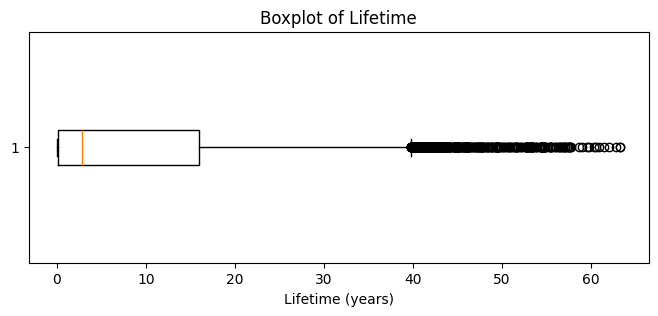

In [8]:
# create a boxplot of the lifetime in years
plt.style.use('default')
plt.figure(figsize=(8, 3))
plt.boxplot(debris_df['LIFETIME']/ 365.25, vert=False)
plt.xlabel('Lifetime (years)')
plt.title('Boxplot of Lifetime')
plt.show()


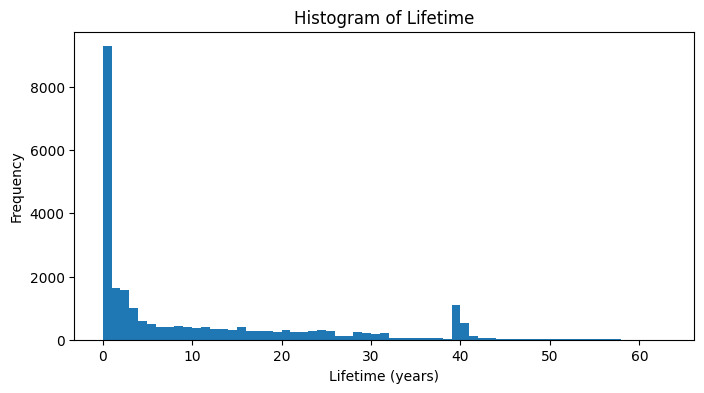

In [ ]:
# create histogram of lifetime in years
plt.figure(figsize=(8, 4))
plt.hist(debris_df['LIFETIME']/365, bins=np.arange(0, max(debris_df['LIFETIME']/365), 1))
plt.xlabel('Lifetime (years)')
plt.ylabel('Frequency')
plt.title('Histogram of Lifetime')
plt.show()


In [9]:
# count objects that have lifetime of less than 365 days
print("Objects with lifetime shorter than one year: ", debris_df[debris_df['LIFETIME'] < 365].shape[0])

Objects with lifetime shorter than one year:  9287


#### It could make sense to drop objects with a lifetime of one year or less but since in this all objects shall be considered, they will stay in the dataset.

### 2. Analyze Epoch Decay Difference

In [10]:
# convert to date and then again to datetime, needed because otherwise the date conversion does not work :/
debris_df['EPOCH'] = pd.to_datetime(debris_df['EPOCH'])
debris_df['DECAY'] = pd.to_datetime(debris_df['DECAY'])

In [11]:
# check difference between Epoch and Decay Date
debris_df['Epoch_Decay_Diff'] = (debris_df['DECAY'] - debris_df['EPOCH']).dt.days
debris_df['Epoch_Decay_Diff'].describe()

count    24474.000000
mean       544.106276
std       1229.113992
min      -7560.000000
25%          5.000000
50%         60.000000
75%        474.750000
max      15766.000000
Name: Epoch_Decay_Diff, dtype: float64

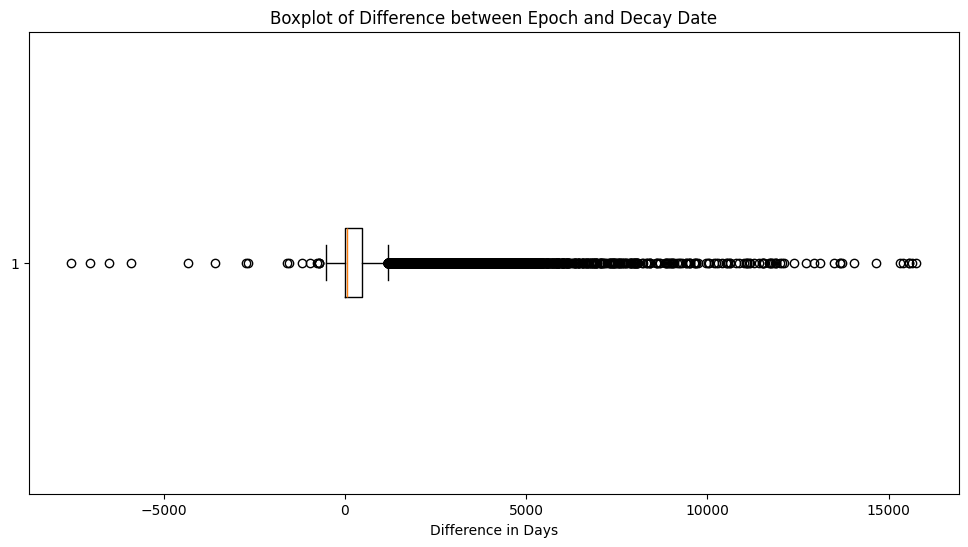

In [12]:
# create a boxplot of the difference between Epoch and Decay Date
plt.figure(figsize=(12, 6))
plt.style.use('default')
plt.boxplot(debris_df['Epoch_Decay_Diff'], vert=False)
plt.xlabel('Difference in Days')
plt.title('Boxplot of Difference between Epoch and Decay Date')
plt.show()

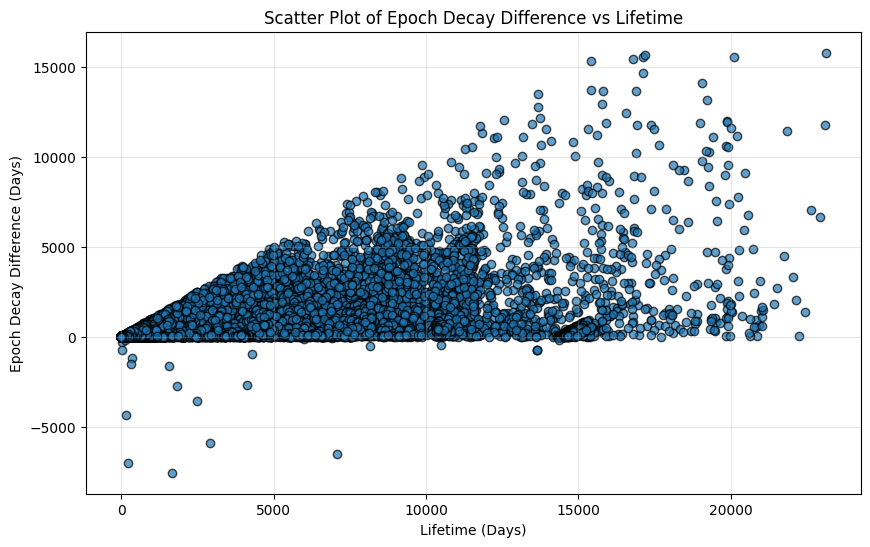

In [14]:
# Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    debris_df['LIFETIME'], 
    debris_df['Epoch_Decay_Diff'], 
    alpha=0.7, 
    edgecolors='k'
)

# Add labels and title
plt.title('Scatter Plot of Epoch Decay Difference vs Lifetime')
plt.xlabel('Lifetime (Days)')
plt.ylabel('Epoch Decay Difference (Days)')
plt.grid(True, alpha=0.3)
plt.show()

### 3. Feature Correlation

In [15]:
# use the preprocessed data from the MLP since that data is normalized
debrisCorr_df = pd.read_csv('../Data/DebrisMLP.csv')
# drop columnns that are not numeric
debrisCorr_df = debrisCorr_df.drop(columns=['NORAD_CAT_ID', 'INTLDES', 'SATNAME', 'OBJECT_TYPE', 'COUNTRY', 'SITE'])

In [16]:
# Calculate the correlation matrix
corr_matrix = debrisCorr_df.corr()

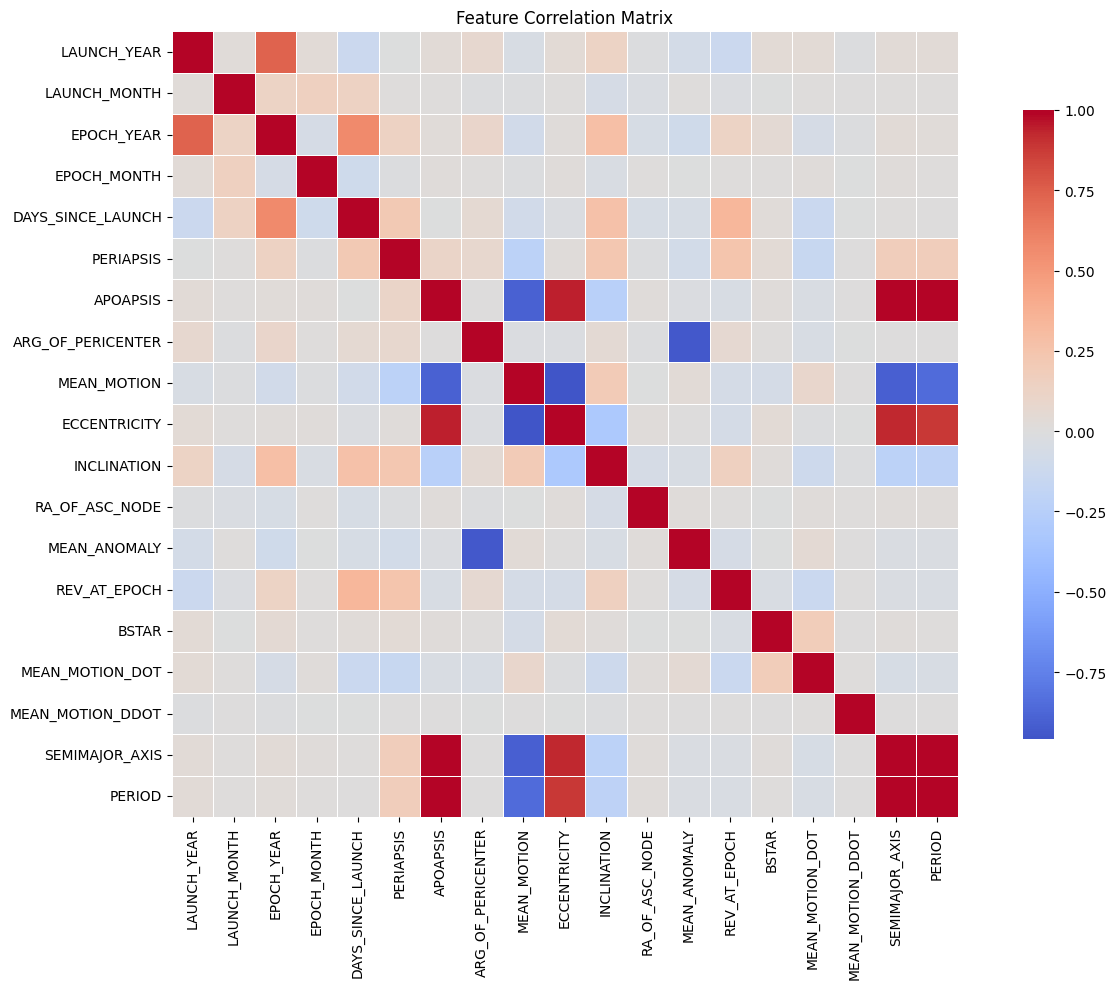

In [17]:
# Heatmap for feature correlation
feature_corr_matrix = corr_matrix.drop('LIFETIME', axis=0).drop('LIFETIME', axis=1)

plt.figure(figsize=(14, 10))
sns.heatmap(feature_corr_matrix, annot=False, cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

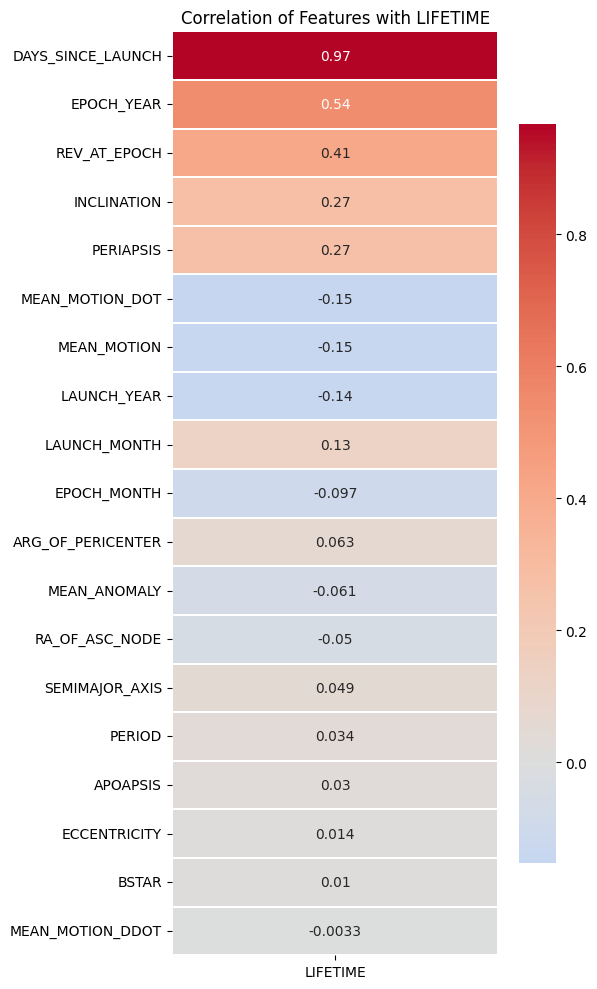

In [18]:
# 2. Heatmap for correlation of all features with the 'LIFETIME' column
lifetime_corr = corr_matrix[['LIFETIME']].drop('LIFETIME', axis=0)
lifetime_corr = lifetime_corr.reindex(lifetime_corr['LIFETIME'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(6, 10))
sns.heatmap(lifetime_corr, annot=True, cmap="coolwarm", center=0,
            linewidths=0.2, cbar_kws={"shrink": 0.8})
plt.title("Correlation of Features with LIFETIME")
plt.tight_layout()
plt.show()